<a href="https://colab.research.google.com/github/raghavvvvv21/sobel-edge-detection-numerical-methods/blob/main/sobel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files


In [ ]:
uploaded = files.upload()

image_name = next(iter(uploaded))

image = cv2.imread(image_name)

if image is None:
    raise ValueError("Could not load image")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

print("Image uploaded successfully!")
print("Image dimensions:", gray.shape)


Saving fe67d34b1d709ad5c7dca40ec9ee8986.jpg to fe67d34b1d709ad5c7dca40ec9ee8986.jpg
Image uploaded successfully!
Image dimensions: (374, 358)


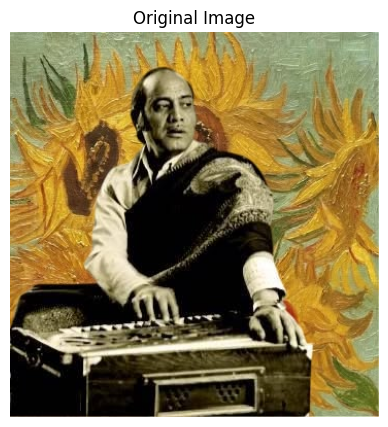

In [ ]:
plt.figure(figsize=(7, 5))

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.show()

In [ ]:
# Sobel kernels

Kx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

Ky = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)


# Manual convolution / cross-correlation

def manual_sobel(image, kernel):

    height, width = image.shape

    padded = np.pad(
        image.astype(np.float32),
        1,
        mode="reflect"
    )

    result = np.zeros(
        (height, width),
        dtype=np.float32
    )

    for i in range(height):
        for j in range(width):

            region = padded[i:i+3, j:j+3]

            result[i, j] = np.sum(region * kernel)

    return result


# Calculate gradients

Gx = manual_sobel(gray, Kx)
Gy = manual_sobel(gray, Ky)

print("Sobel gradients calculated!")

Sobel gradients calculated!


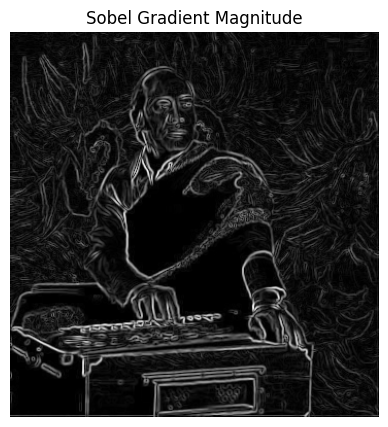

In [ ]:
magnitude = np.sqrt(Gx**2 + Gy**2)

normalized = (
    magnitude / magnitude.max() * 255
).astype(np.uint8)

plt.figure(figsize=(7, 5))

plt.imshow(normalized, cmap="gray")
plt.title("Sobel Gradient Magnitude")
plt.axis("off")

plt.show()


In [ ]:
thresholds = [30, 60, 100]

edge_maps = {}

for T in thresholds:

    edges = np.where(
        normalized >= T,
        255,
        0
    ).astype(np.uint8)

    edge_maps[T] = edges

    percentage = (
        np.count_nonzero(edges) / edges.size
    ) * 100

    print(f"Threshold: {T}")
    print(f"Edge pixels: {percentage:.2f}%")
    print("----------------------")

Threshold: 30
Edge pixels: 26.41%
----------------------
Threshold: 60
Edge pixels: 10.58%
----------------------
Threshold: 100
Edge pixels: 4.07%
----------------------


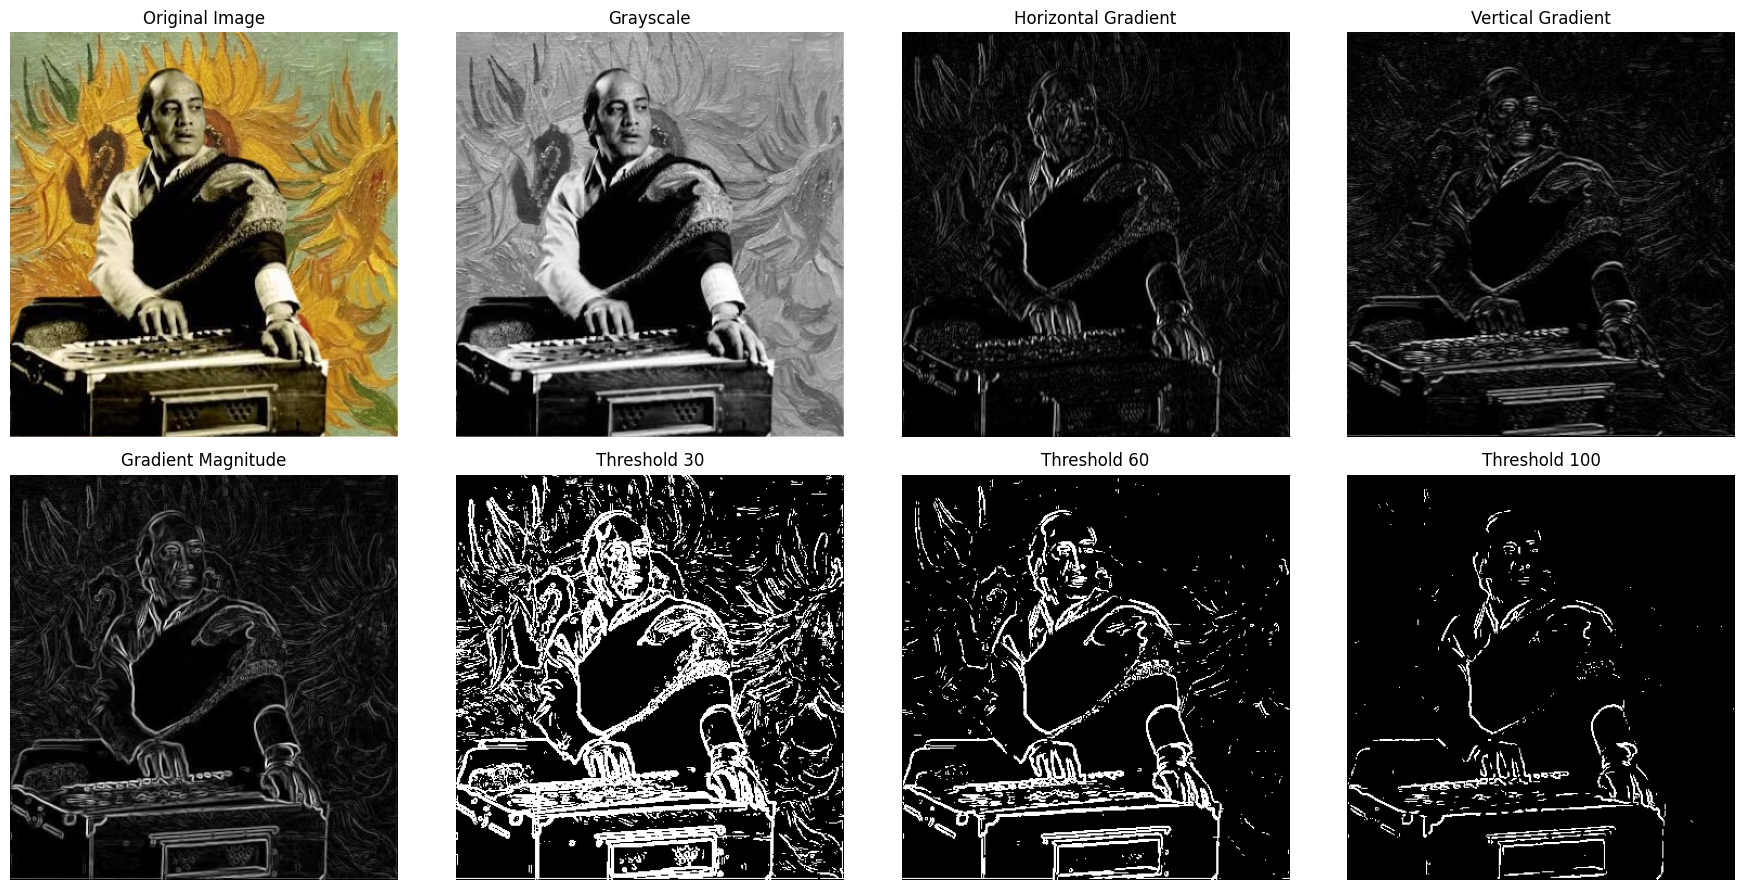

In [ ]:

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

results = [
    (image, "Original Image"),
    (gray, "Grayscale"),
    (np.abs(Gx), "Horizontal Gradient"),
    (np.abs(Gy), "Vertical Gradient"),
    (normalized, "Gradient Magnitude"),
    (edge_maps[30], "Threshold 30"),
    (edge_maps[60], "Threshold 60"),
    (edge_maps[100], "Threshold 100")
]

for ax, (img, title) in zip(axes.flat, results):

    ax.imshow(
        img,
        cmap="gray" if img.ndim == 2 else None
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# OpenCV reference implementation

opencv_Gx = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    Kx,
    borderType=cv2.BORDER_REFLECT_101
)

opencv_Gy = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    Ky,
    borderType=cv2.BORDER_REFLECT_101
)

# Calculate differences

difference_x = np.max(np.abs(Gx - opencv_Gx))
difference_y = np.max(np.abs(Gy - opencv_Gy))

print("Manual vs OpenCV comparison")
print("--------------------------------")
print("Maximum Gx difference:", difference_x)
print("Maximum Gy difference:", difference_y)

if np.allclose(Gx, opencv_Gx) and np.allclose(Gy, opencv_Gy):
    print("Verification successful!")
else:
    print("Differences detected. Further investigation required.")

Manual vs OpenCV comparison
--------------------------------
Maximum Gx difference: 0.0
Maximum Gy difference: 0.0
Verification successful!


In [ ]:

# Fair noise comparison using a fixed normalization reference

reference_max = magnitude.max()
threshold = 60

np.random.seed(42)

noise_levels = [0, 10, 25, 50]

results = []

for noise_std in noise_levels:

    if noise_std == 0:
        noisy_image = gray.copy().astype(np.uint8)
    else:
        noise = np.random.normal(
            0, noise_std, gray.shape
        )

        noisy_image = np.clip(
            gray.astype(np.float32) + noise,
            0, 255
        ).astype(np.uint8)

    noisy_Gx = manual_sobel(noisy_image, Kx)
    noisy_Gy = manual_sobel(noisy_image, Ky)

    noisy_magnitude = np.sqrt(
        noisy_Gx**2 + noisy_Gy**2
    )

    # Use the same reference maximum for all images
    noisy_normalized = np.clip(
        noisy_magnitude / reference_max * 255,
        0, 255
    ).astype(np.uint8)

    noisy_edges = np.where(
        noisy_normalized >= threshold,
        255, 0
    ).astype(np.uint8)

    percentage = (
        np.count_nonzero(noisy_edges) /
        noisy_edges.size
    ) * 100

    results.append((noise_std, percentage))

    print(
        f"Noise SD: {noise_std:2d} | "
        f"Edge pixels: {percentage:.2f}%"
    )


Noise SD:  0 | Edge pixels: 10.58%
Noise SD: 10 | Edge pixels: 11.07%
Noise SD: 25 | Edge pixels: 16.44%
Noise SD: 50 | Edge pixels: 40.05%


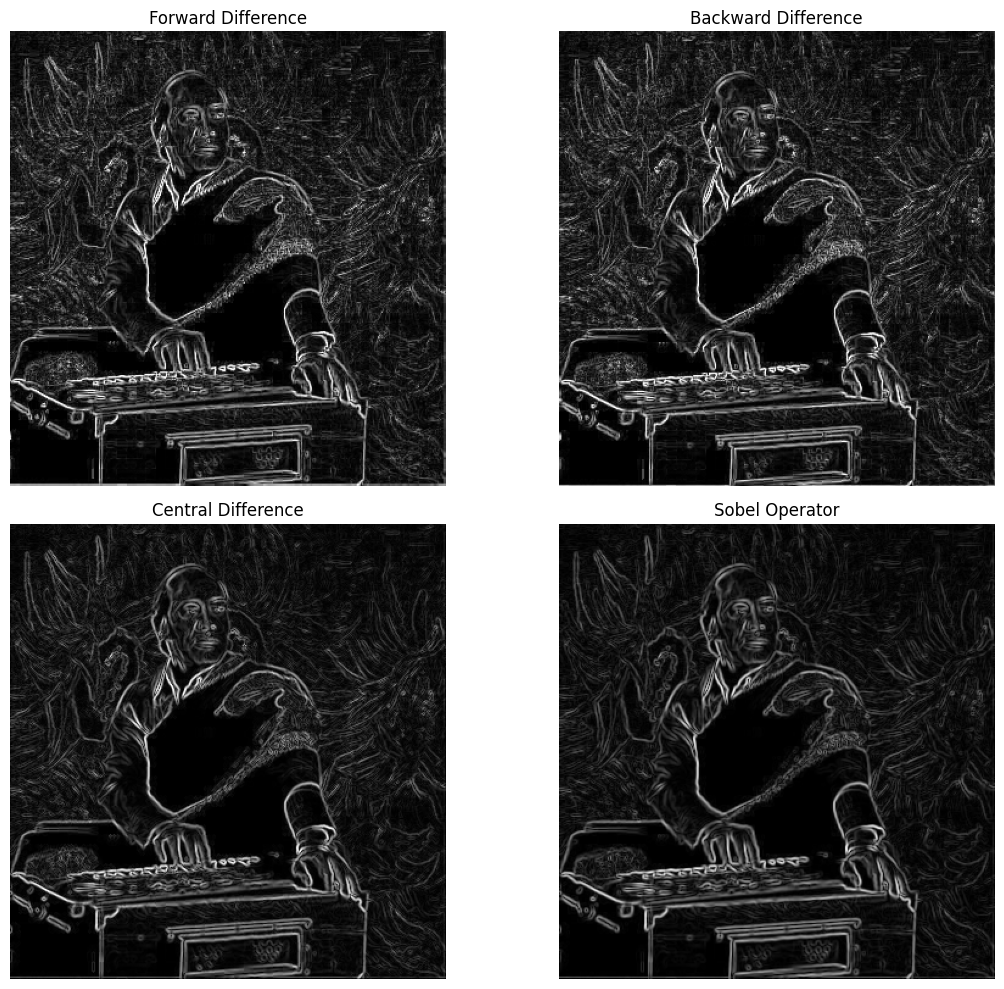

In [ ]:

# Experiment 4: Finite Difference Comparison

img = gray.astype(np.float32)

# Padding for boundary handling
padded = np.pad(img, 1, mode="reflect")

# Forward differences
Fx = padded[1:-1, 2:] - padded[1:-1, 1:-1]
Fy = padded[2:, 1:-1] - padded[1:-1, 1:-1]

# Backward differences
Bx = padded[1:-1, 1:-1] - padded[1:-1, :-2]
By = padded[1:-1, 1:-1] - padded[:-2, 1:-1]

# Central differences
Cx = (padded[1:-1, 2:] - padded[1:-1, :-2]) / 2
Cy = (padded[2:, 1:-1] - padded[:-2, 1:-1]) / 2

# Gradient magnitudes
F_mag = np.sqrt(Fx**2 + Fy**2)
B_mag = np.sqrt(Bx**2 + By**2)
C_mag = np.sqrt(Cx**2 + Cy**2)

# Sobel gradient magnitude
S_mag = np.sqrt(Gx**2 + Gy**2) / 8

# Normalize all using a common reference
reference = S_mag.max()

def normalize_gradient(data):
    return np.clip(
        data / reference * 255, 0, 255
    ).astype(np.uint8)

F_display = normalize_gradient(F_mag)
B_display = normalize_gradient(B_mag)
C_display = normalize_gradient(C_mag)
S_display = normalize_gradient(S_mag)

# Display comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

comparisons = [
    (F_display, "Forward Difference"),
    (B_display, "Backward Difference"),
    (C_display, "Central Difference"),
    (S_display, "Sobel Operator")
]

for ax, (result, title) in zip(axes.flat, comparisons):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Quantitative comparison of four methods

methods = {
    "Forward Difference": F_mag,
    "Backward Difference": B_mag,
    "Central Difference": C_mag,
    "Sobel Operator": S_mag
}

threshold = 60

print("Method Comparison")
print("-" * 55)

for name, gradient in methods.items():

    normalized_gradient = np.clip(
        gradient / reference * 255,
        0, 255
    )

    edges = normalized_gradient >= threshold

    percentage = np.mean(edges) * 100

    print(
        f"{name:22s} : {percentage:.2f}%"
    )


Method Comparison
-------------------------------------------------------
Forward Difference     : 17.96%
Backward Difference    : 17.69%
Central Difference     : 12.19%
Sobel Operator         : 10.58%


Gaussian Smoothing Comparison
---------------------------------------------
Without smoothing : 40.25%
3x3 Gaussian      : 9.43%
5x5 Gaussian      : 6.49%


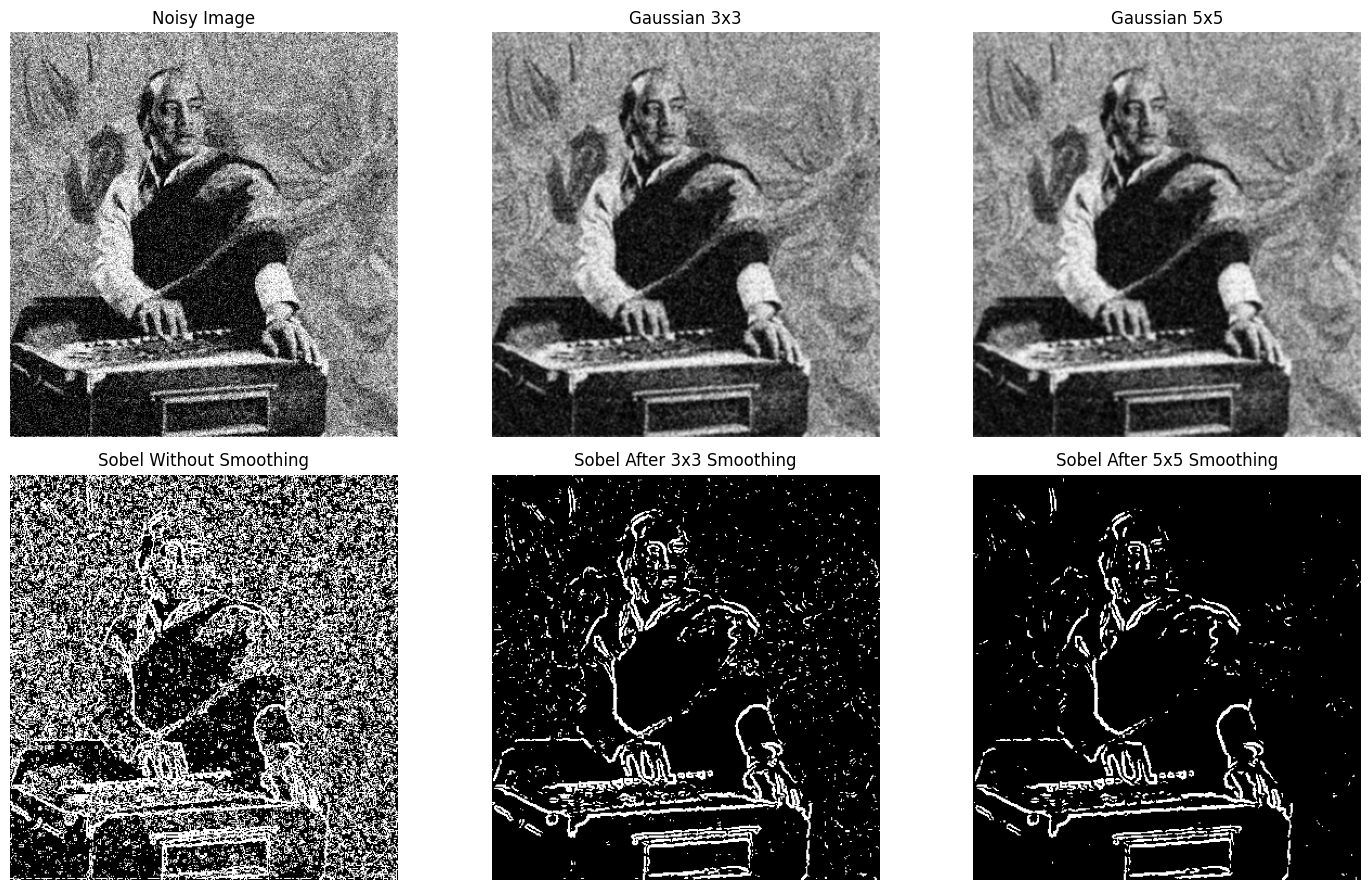